## Phase 4: NLP-Based Feature Engineering
**The goal is : Transform the textual information in job postings into clean, structured, and numerical features that can be analyzed and used by machine-learning algorithms**

### **Step 1: Inspect the text data**

**1.1-Load our cleaned data**

In [101]:
import pandas as pd
import numpy as np

df_clean=pd.read_csv("../data/processed/ai_jobs_clean.csv")


**1.2-Inspect the skills required column**

In [102]:
print(df_clean["skills required"].head(15).tolist())

print("\nMost frequent values:")
print(df_clean["skills required"].value_counts().head(10))

print("\nData type:")
print(df_clean["skills required"].dtype)

['Unknown', 'Big Data, Database', 'Unknown', 'Unknown', 'Unknown', 'Big Data, Cloud', 'Database', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Machine Learning', 'Excel']

Most frequent values:
skills required
Unknown               788
Stat                   49
Machine Learning       36
Data Mining            35
Database               34
Python                 34
Excel                  23
Data Visualization     22
Ai                     22
Big Data               20
Name: count, dtype: int64

Data type:
str


*-> Pandas treats this column as text, even though each cell can contain several different skills. We need to separate those skills before turning them into features.*

**1.3-Measure the unknown information**

In [103]:
skills_text = (
    df_clean["skills required"]
    .astype("string")
    .str.strip()
)
unknown_mask=(
    skills_text
    .str.casefold()
    .isin(["unknown","","none","nan"])
)
print("Total job posting : ",len(df_clean))
print("Unknown skill entries:",unknown_mask.sum())

print("Unknown percentage:",round(unknown_mask.mean() * 100,2),"%")

Total job posting :  1361
Unknown skill entries: 788
Unknown percentage: 57.9 %


**1.4-Inspect the structure of recorded skills**

In [104]:
recorded_skills = df_clean.loc[
    ~unknown_mask,
    "skills required"
]

print(recorded_skills.head(10).to_list())

['Big Data, Database', 'Big Data, Cloud', 'Database', 'Machine Learning', 'Excel', 'Stat', 'Sql', 'Sql , Database', 'Database', 'Stat']


**1.5-Verifying the selection**

In [105]:
print("Recorded entries:", len(recorded_skills))
print("Unknown values remaining:",
      recorded_skills.astype("string")
      .str.strip()
      .str.casefold()
      .eq("unknown")
      .sum())

Recorded entries: 573
Unknown values remaining: 0


### **Step 2:Text Preprocessing**

**2.1—Create a separate working column**

In [106]:
df_phase4=df_clean.copy()
df_phase4["skills_text"] = (
    df_phase4["skills required"]
    .astype("string") 
)

**2.2—Normalize capitalization and whitespace**

In [107]:
df_phase4["skills_text"]=(
    df_phase4["skills_text"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s*,\s*",",",regex=True)
)

**2.3—Standardize unknown entries**

In [108]:
unknown_values=["unknown","none","nan",""]

df_phase4["skills_text"]=(
    df_phase4["skills_text"]
    .replace(unknown_values,pd.NA)
)

**2.4—Check the results**

In [109]:
df_phase4[["skills required" , "skills_text"]].head(15)

,skills required,skills_text
0,Unknown,<NA>
1,"Big Data, Database","big data,database"
2,Unknown,<NA>
3,Unknown,<NA>
4,Unknown,<NA>
5,"Big Data, Cloud","big data,cloud"
6,Database,database
7,Unknown,<NA>
8,Unknown,<NA>
9,Unknown,<NA>


**Verifying the missing values**

In [110]:
print(
    df_phase4["skills_text"].isna().sum()
)

print(
    round(
        df_phase4["skills_text"].isna().mean() * 100,
        2
    )
)

788
57.9


**2.5—Verify text consistency**

*Let's check whether the preprocessing worked*

In [111]:
print("Original data type:")
print(df_phase4["skills required"].dtype)

print("\nProcessed data type:")
print(df_phase4["skills_text"].dtype)

print("\nExamples of processed values:")
print(
    df_phase4["skills_text"]
    .dropna()
    .head(10)
    .to_list()
)

Original data type:
str

Processed data type:
string

Examples of processed values:
['big data,database', 'big data,cloud', 'database', 'machine learning', 'excel', 'stat', 'sql', 'sql,database', 'database', 'stat']


### **Step 3:Build the Skill Vocabulary**

**3.1-Split the text into individual skills**

In [112]:
skills_lists = (
    df_phase4["skills_text"]
    .dropna()
    .str.split(",")
)

print(skills_lists.head(10).to_list())

[['big data', 'database'], ['big data', 'cloud'], ['database'], ['machine learning'], ['excel'], ['stat'], ['sql'], ['sql', 'database'], ['database'], ['stat']]


**3.2-Put all skills into one collection**

In [113]:
all_skills = (
    skills_lists
    .explode()
    .str.strip()
)

print(all_skills.head(15).to_list())

['big data', 'database', 'big data', 'cloud', 'database', 'machine learning', 'excel', 'stat', 'sql', 'sql', 'database', 'database', 'stat', 'dashboard', 'etl']


**3.3-Create the unique skill vocabulary**

In [114]:
skill_vocabulary = sorted(
    set(all_skills.dropna())
)

print("Number of unique skills:", len(skill_vocabulary))

print("\nSkill vocabulary:")
print(skill_vocabulary)

Number of unique skills: 26

Skill vocabulary:
['ai', 'artificial intelligence', 'big data', 'cloud', 'computer vision', 'dashboard', 'data mining', 'data structure', 'data visualization', 'database', 'deep learning', 'deployment', 'etl', 'excel', 'machine learning', 'neural network', 'nlp', 'powerbi', 'preprocessing', 'python', 'pytorch', 'r', 'sql', 'stat', 'tableau', 'tensorflow']


**3.4-Count the occurrences of each skill**

In [115]:
skill_counts = all_skills.value_counts()

print("Top 20 most frequent skills:")
print(skill_counts.head(20))

Top 20 most frequent skills:
skills_text
stat                  100
python                 88
machine learning       62
data mining            58
data visualization     57
database               52
ai                     47
big data               43
excel                  41
deep learning          34
sql                    33
data structure         29
etl                    25
deployment             20
dashboard              17
preprocessing          15
pytorch                15
tableau                13
r                      13
cloud                  11
Name: count, dtype: int64


**3.5-Validate the vocabulary**

In [116]:
print("Empty skill entries:",
      all_skills.eq("").sum())

print("Unknown entries:",
      all_skills.str.casefold().eq("unknown").sum())

print("Total skill mentions:", len(all_skills))

print("Unique skills:", len(skill_vocabulary))

Empty skill entries: 0
Unknown entries: 0
Total skill mentions: 808
Unique skills: 26


### **Step 4 :Skill-Based Feature Extraction**

**4.1-Choose the skills to encode**

In [117]:
print("Total unique skills:", len(skill_vocabulary))
print(skill_vocabulary)

Total unique skills: 26
['ai', 'artificial intelligence', 'big data', 'cloud', 'computer vision', 'dashboard', 'data mining', 'data structure', 'data visualization', 'database', 'deep learning', 'deployment', 'etl', 'excel', 'machine learning', 'neural network', 'nlp', 'powerbi', 'preprocessing', 'python', 'pytorch', 'r', 'sql', 'stat', 'tableau', 'tensorflow']


**4.2-Create a binary feature matrix**

In [118]:

# Create binary features using the correct separator
skill_features = pd.DataFrame(
    {
        f"has_{skill.replace(' ', '_')}": (
            df_phase4["skills_text"]
            .apply(
                lambda text: int(
                    skill in [s.strip() for s in text.split(",")]
                )
                if pd.notna(text)
                else 0
            )
        )
        for skill in skill_vocabulary
    },
    index=df_phase4.index
)

# Keep only postings with recorded skills
known_mask = df_phase4["skills_text"].notna()

X_skills = skill_features.loc[known_mask].copy()
job_categories = df_phase4.loc[known_mask, "job_category"].copy()

print("Feature matrix shape:", X_skills.shape)

# Count how many skills each posting has in the feature matrix
skills_per_row = X_skills.sum(axis=1)

print("\nSkills detected per posting:")
print(skills_per_row.describe())

print("\nNumber of postings by detected skill count:")
print(skills_per_row.value_counts().sort_index())

print("\nNumber of unique skill profiles:", len(X_skills.drop_duplicates()))


Feature matrix shape: (573, 26)

Skills detected per posting:
count    573.000000
mean       1.410122
std        0.695416
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        5.000000
dtype: float64

Number of postings by detected skill count:
1    392
2    138
3     36
4      3
5      4
Name: count, dtype: int64

Number of unique skill profiles: 136


**4.3-Verify the features**

In [119]:
print(skill_features.dtypes.value_counts())

print(
    "Unique feature values:",
    np.unique(skill_features.to_numpy())
)

int64    26
Name: count, dtype: int64
Unique feature values: [0 1]


**4.4-Combine the features with the job data**

In [120]:
df_features = pd.concat(
    [
        df_phase4,
        skill_features
    ],
    axis=1
)

print("Original shape:", df_phase4.shape)
print("New shape:", df_features.shape)

df_features.head()

Original shape: (1361, 8)
New shape: (1361, 34)


,job title,company,region,skills required,is remote?,is fresher?,job_category,skills_text,has_ai,has_artificial_intelligence,...,has_nlp,has_powerbi,has_preprocessing,has_python,has_pytorch,has_r,has_sql,has_stat,has_tableau,has_tensorflow
0,Data analyst,BP Energy,Pune,Unknown,no,no,Data analyst,<NA>,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Data analyst,Arcadis,Bengaluru,"Big Data, Database",no,no,Data analyst,"big data,database",0,0,...,0,0,0,0,0,0,0,0,0,0
2,Data analyst,Scan Holdings Pvt. Limited,Delhi,Unknown,no,unknown,Data analyst,<NA>,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Data analyst,BOEING,Bengaluru,Unknown,no,unknown,Data analyst,<NA>,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Data analyst,Boston Consulting Group,New Delhi,Unknown,no,unknown,Data analyst,<NA>,0,0,...,0,0,0,0,0,0,0,0,0,0


**4.5-Evaluate the coverage of the features**

In [121]:
df_features["has_recorded_skills"] = (
    df_features["skills_text"].notna()
)

print(
    df_features["has_recorded_skills"]
    .value_counts()
)

print(
    df_features.groupby(
        "has_recorded_skills"
    )["job_category"].value_counts()
)

has_recorded_skills
False    788
True     573
Name: count, dtype: int64
has_recorded_skills  job_category  
False                Data scientist    368
                     Data analyst      365
                     ML engineer        55
True                 Data scientist    252
                     Data analyst      220
                     ML engineer       101
Name: count, dtype: int64


### **Text Vectorization (Bag of Words and TF-IDF)**

**5.1-Understand the two techniques**

*1. **Bag of Words (BoW)**:Counts how often each word appears in a job's skills text.*

*2. **TF-IDF**:Gives more weight to terms that are important in a particular job posting and less weight to terms that appear in many postings*


**5.2-Create the Bag of Words matrix**

In [122]:

from sklearn.feature_extraction.text import CountVectorizer

# Use only rows with recorded skills
skills_text_valid = df_phase4["skills_text"].dropna()

# Build the Bag of Words model
bow_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

bow_matrix = bow_vectorizer.fit_transform(skills_text_valid)

# Convert to a DataFrame for easier inspection
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=skills_text_valid.index
)

print("BoW matrix shape:", bow_df.shape)
print("\nFirst five rows:")
print(bow_df.head())


BoW matrix shape: (573, 31)

First five rows:
    ai  artificial  big  cloud  computer  dashboard  data  database  deep  \
1    0           0    1      0         0          0     1         1     0   
5    0           0    1      1         0          0     1         0     0   
6    0           0    0      0         0          0     0         1     0   
13   0           0    0      0         0          0     0         0     0   
14   0           0    0      0         0          0     0         0     0   

    deployment  ...  python  pytorch  r  sql  stat  structure  tableau  \
1            0  ...       0        0  0    0     0          0        0   
5            0  ...       0        0  0    0     0          0        0   
6            0  ...       0        0  0    0     0          0        0   
13           0  ...       0        0  0    0     0          0        0   
14           0  ...       0        0  0    0     0          0        0   

    tensorflow  vision  visualization  
1     

**5.3-Create the TF-IDF matrix**

In [123]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = tfidf_vectorizer.fit_transform(skills_text_valid)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=skills_text_valid.index
)

print("TF-IDF matrix shape:", tfidf_df.shape)
print("\nFirst five rows:")
print(tfidf_df.head())


TF-IDF matrix shape: (573, 31)

First five rows:
     ai  artificial       big    cloud  computer  dashboard      data  \
1   0.0         0.0  0.664222  0.00000       0.0        0.0  0.403034   
5   0.0         0.0  0.556505  0.75913       0.0        0.0  0.337674   
6   0.0         0.0  0.000000  0.00000       0.0        0.0  0.000000   
13  0.0         0.0  0.000000  0.00000       0.0        0.0  0.000000   
14  0.0         0.0  0.000000  0.00000       0.0        0.0  0.000000   

    database  deep  deployment  ...  python  pytorch    r  sql  stat  \
1   0.629581   0.0         0.0  ...     0.0      0.0  0.0  0.0   0.0   
5   0.000000   0.0         0.0  ...     0.0      0.0  0.0  0.0   0.0   
6   1.000000   0.0         0.0  ...     0.0      0.0  0.0  0.0   0.0   
13  0.000000   0.0         0.0  ...     0.0      0.0  0.0  0.0   0.0   
14  0.000000   0.0         0.0  ...     0.0      0.0  0.0  0.0   0.0   

    structure  tableau  tensorflow  vision  visualization  
1         0.0      

**5.4-Compare the matrices**

In [124]:

print("Number of recorded-skill postings:", len(skills_text_valid))
print("Binary skill features:", skill_features.shape[1])
print("BoW vocabulary size:", bow_df.shape[1])
print("TF-IDF vocabulary size:", tfidf_df.shape[1])

print("\nBoW values:")
print(bow_df.iloc[:3, :5])

print("\nTF-IDF values:")
print(tfidf_df.iloc[:3, :5])


Number of recorded-skill postings: 573
Binary skill features: 26
BoW vocabulary size: 31
TF-IDF vocabulary size: 31

BoW values:
   ai  artificial  big  cloud  computer
1   0           0    1      0         0
5   0           0    1      1         0
6   0           0    0      0         0

TF-IDF values:
    ai  artificial       big    cloud  computer
1  0.0         0.0  0.664222  0.00000       0.0
5  0.0         0.0  0.556505  0.75913       0.0
6  0.0         0.0  0.000000  0.00000       0.0


### **Step 6:Analyze Engineered Features & Skill Combinations**

**6.1-Identify the most common skills**

In [125]:

# Count how many postings mention each skill
skill_frequency = skill_features.sum().sort_values(ascending=False)

# Show the 15 most frequent skills
top_skills = skill_frequency.head(15)

print("Top 15 skills:")
print(top_skills)


Top 15 skills:
has_stat                  100
has_python                 88
has_machine_learning       62
has_data_mining            58
has_data_visualization     57
has_database               52
has_ai                     47
has_big_data               43
has_excel                  41
has_deep_learning          34
has_sql                    33
has_data_structure         29
has_etl                    25
has_deployment             20
has_dashboard              17
dtype: int64


**6.2-Calculate skill prevalence among postings with known skills**

In [126]:
# Keep only postings with recorded skills
known_skill_features = skill_features.loc[
    df_phase4["skills_text"].notna()
]

# Calculate the percentage of known-skill postings mentioning each skill
skill_prevalence = (
    known_skill_features.mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Top 15 skills by prevalence (%):")
print(skill_prevalence.head(15).round(2))


Top 15 skills by prevalence (%):
has_stat                  17.45
has_python                15.36
has_machine_learning      10.82
has_data_mining           10.12
has_data_visualization     9.95
has_database               9.08
has_ai                     8.20
has_big_data               7.50
has_excel                  7.16
has_deep_learning          5.93
has_sql                    5.76
has_data_structure         5.06
has_etl                    4.36
has_deployment             3.49
has_dashboard              2.97
dtype: float64


**6.3-Find skills that frequently appear together**

In [127]:
from itertools import combinations
from collections import Counter

# Split the recorded skills into lists
skills_lists = (
    df_phase4.loc[
        df_phase4["skills_text"].notna(),
        "skills_text"
    ]
    .str.split(",")
    .apply(lambda skills: sorted(set(
        skill.strip() for skill in skills if skill.strip()
    )))
)

# Count each pair once per posting
pair_counts = Counter()

for skills in skills_lists:
    pair_counts.update(combinations(skills, 2))

# Display the 15 most frequent pairs
top_pairs = pair_counts.most_common(15)

for pair, count in top_pairs:
    print(f"{pair[0]} + {pair[1]}: {count} postings")


python + stat: 13 postings
machine learning + stat: 12 postings
machine learning + python: 11 postings
python + r: 10 postings
data mining + stat: 10 postings
data visualization + tableau: 9 postings
data visualization + stat: 8 postings
pytorch + tensorflow: 8 postings
excel + python: 6 postings
data visualization + excel: 6 postings
big data + python: 6 postings
deep learning + stat: 6 postings
database + sql: 5 postings
data visualization + python: 5 postings
excel + stat: 5 postings


**6.4-Compare skills across job categories**

In [128]:
# Select only postings with known skills
known_rows = df_phase4["skills_text"].notna()

category_skill_features = skill_features.loc[known_rows].copy()
category_skill_features["job_category"] = (
    df_phase4.loc[known_rows, "job_category"]
)

# Calculate the percentage of postings in each category
# that mention each skill
category_skill_prevalence = (
    category_skill_features
    .groupby("job_category")
    .mean(numeric_only=True)
    .mul(100)
    .round(2)
)

print(category_skill_prevalence)


                has_ai  has_artificial_intelligence  has_big_data  has_cloud  \
job_category                                                                   
Data analyst      0.00                         0.00          5.45        5.0   
Data scientist    2.78                         0.79         11.51        0.0   
ML engineer      39.60                         0.00          1.98        0.0   

                has_computer_vision  has_dashboard  has_data_mining  \
job_category                                                          
Data analyst                   0.00           5.91             8.64   
Data scientist                 0.00           1.59            15.48   
ML engineer                    5.94           0.00             0.00   

                has_data_structure  has_data_visualization  has_database  ...  \
job_category                                                              ...   
Data analyst                  4.55                   17.27         23.64  ...   


**6.5-Visualize the most common skills**

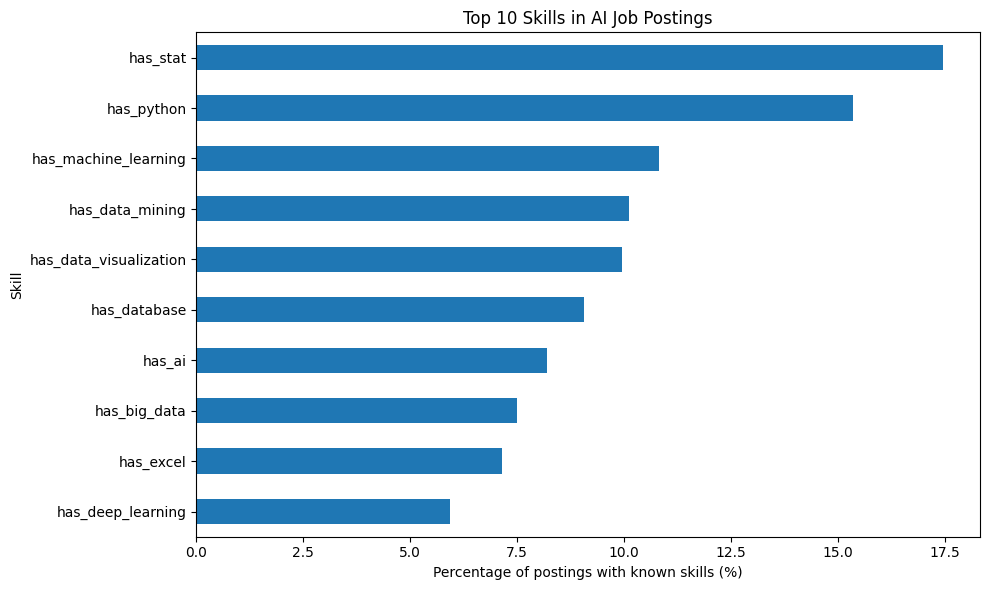

In [129]:
import matplotlib.pyplot as plt

top_10_prevalence = skill_prevalence.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10_prevalence.plot(kind="barh")

plt.title("Top 10 Skills in AI Job Postings")
plt.xlabel("Percentage of postings with known skills (%)")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()


### **Step 7: Validate and Prepare the Final Feature Matrix for Clustering**

**7.1-Check the shape of our feature matrices**

In [130]:
print("Original cleaned dataset:", df_phase4.shape)
print("Binary skill features:", skill_features.shape)
print("Bag of Words features:", bow_df.shape)
print("TF-IDF features:", tfidf_df.shape)

print("\nMissing values in binary features:")
print(skill_features.isna().sum().sum())

print("\nMissing values in BoW:")
print(bow_df.isna().sum().sum())

print("\nMissing values in TF-IDF:")
print(tfidf_df.isna().sum().sum())

Original cleaned dataset: (1361, 8)
Binary skill features: (1361, 26)
Bag of Words features: (573, 31)
TF-IDF features: (573, 31)

Missing values in binary features:
0

Missing values in BoW:
0

Missing values in TF-IDF:
0


**7.2-Check whether the binary features are valid**

In [131]:
print("Unique binary values:")
print(np.unique(skill_features.to_numpy()))

print("\nAre all binary features 0 or 1?")
print(skill_features.isin([0, 1]).all().all())

print("\nDuplicate feature columns:")
print(skill_features.columns.duplicated().sum())

Unique binary values:
[0 1]

Are all binary features 0 or 1?
True

Duplicate feature columns:
0


**7.3-Check the unknown-skills problem**

In [132]:
# Identify postings whose skill information is unknown
unknown_mask = df_phase4["skills_text"].isna()

# Count postings where every binary skill feature is zero
all_zero_mask = skill_features.sum(axis=1).eq(0)

print("Postings with unknown skills:", unknown_mask.sum())
print("Postings with all-zero skill features:", all_zero_mask.sum())

print(
    "Unknown postings represented by all-zero features:",
    (unknown_mask & all_zero_mask).sum()
)

print(
    "Postings with known skills but all-zero features:",
    ((~unknown_mask) & all_zero_mask).sum()
)

Postings with unknown skills: 788
Postings with all-zero skill features: 788
Unknown postings represented by all-zero features: 788
Postings with known skills but all-zero features: 0


**7.4-Prepare the final feature matrix**

In [133]:
# Keep postings with recorded skills only
known_mask = df_phase4["skills_text"].notna()

# Select the corresponding binary feature rows
X_skills = skill_features.loc[known_mask].copy()

# Keep job categories separately for later interpretation
job_categories = df_phase4.loc[known_mask, "job_category"].copy()

print("Final binary feature matrix:", X_skills.shape)
print("Missing values:", X_skills.isna().sum().sum())
print("Duplicate rows:", X_skills.duplicated().sum())
print("\nJob category distribution:")
print(job_categories.value_counts())


Final binary feature matrix: (573, 26)
Missing values: 0
Duplicate rows: 437

Job category distribution:
job_category
Data scientist    252
Data analyst      220
ML engineer       101
Name: count, dtype: int64


**7.5-Save the engineered features**

In [134]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

X_skills.to_csv(
    output_dir / "ai_jobs_skill_features.csv",
    index=True
)

print("Feature matrix saved successfully!")


Feature matrix saved successfully!


## Phase5:Machine Learning: Job Clustering with K-Means

**1 — Prepare and validate the dataset**

In [135]:
# Check that the feature matrix exists
print("Feature matrix shape:", X_skills.shape)

# Check for missing values
print("Missing values:", X_skills.isna().sum().sum())

# Check feature values
print("Unique values:", np.unique(X_skills.to_numpy()))

# Check the number of unique skill profiles
print("Unique skill profiles:", X_skills.drop_duplicates().shape[0])


Feature matrix shape: (573, 26)
Missing values: 0
Unique values: [0 1]
Unique skill profiles: 136


**2 — Understand K-Means**

*K-Means is an unsupervised Machine Learning algorithm that groups similar observations into \(k\) clusters.*

*It works roughly like this:*

**1. Choose the number of clusters, \(k\).**

**2. Initialize \(k\) cluster centers, called centroids.**

**3. Assign each job posting to its nearest centroid.**

**4. Update the centroids based on the assigned postings.**

**5. Repeat until the assignments stabilize or the algorithm reaches its stopping limit.**

*For our project, each job posting is represented by a vector of skill indicators. K-Means attempts to group postings with similar skill patterns.*

*One limitation to remember: K-Means uses Euclidean distance. It is a useful baseline for our binary features, but it may not be the best clustering method for every type of sparse skill data.*

**3 — Find the number of clusters**

*We don't want to choose \(k\) randomly. We'll test different values and use two evaluation methods.*

**3.1 — Elbow method**

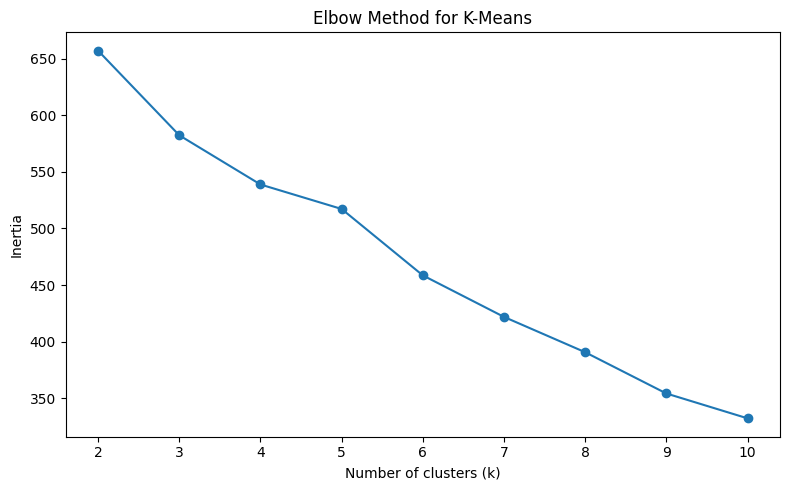

In [136]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_skills)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


**3.2 — Silhouette score**

k = 2, silhouette score = 0.1669
k = 3, silhouette score = 0.1950
k = 4, silhouette score = 0.2139
k = 5, silhouette score = 0.2536
k = 6, silhouette score = 0.2875
k = 7, silhouette score = 0.3360
k = 8, silhouette score = 0.3603
k = 9, silhouette score = 0.4023
k = 10, silhouette score = 0.4237


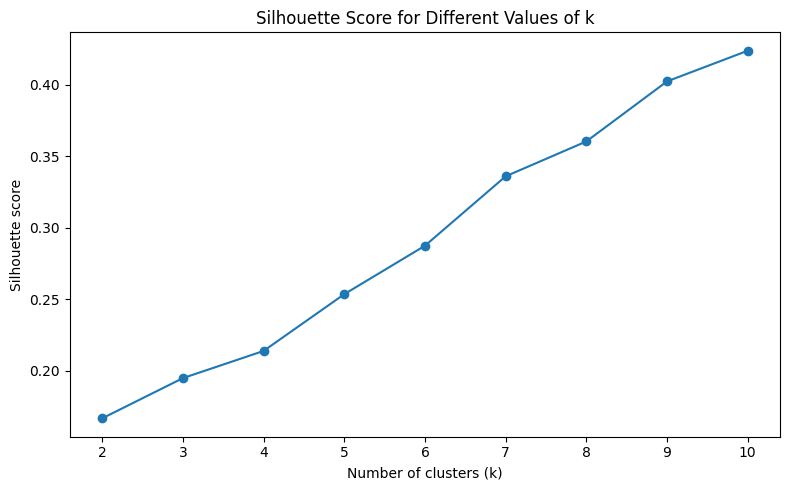

In [137]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_skills)
    score = silhouette_score(X_skills, labels)

    silhouette_scores.append(score)
    print(f"k = {k}, silhouette score = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Score for Different Values of k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()


In [138]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

candidate_ks = [3, 5, 7, 10]
cluster_comparison = []

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_skills)
    sizes = pd.Series(labels).value_counts()

    cluster_comparison.append({
        "k": k,
        "silhouette_score": silhouette_score(X_skills, labels),
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max(),
        "clusters_with_fewer_than_10_jobs": (sizes < 10).sum()
    })

comparison_df = pd.DataFrame(cluster_comparison)

print(comparison_df.round(4).to_string(index=False))


 k  silhouette_score  smallest_cluster  largest_cluster  clusters_with_fewer_than_10_jobs
 3            0.1950                87              398                                 0
 5            0.2536                47              297                                 0
 7            0.3360                47              183                                 0
10            0.4237                29              134                                 0


In [144]:
from sklearn.cluster import KMeans
import pandas as pd

# Fit the model with 10 clusters
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_10.fit_predict(X_skills)

# Create a copy of the skill features and attach cluster labels
clustered_jobs = X_skills.copy()
clustered_jobs["cluster"] = cluster_labels

# Identify the most frequent skills in each cluster
skill_columns = X_skills.columns

for cluster_id in sorted(clustered_jobs["cluster"].unique()):
    cluster_data = clustered_jobs[
        clustered_jobs["cluster"] == cluster_id
    ]

    skill_counts = cluster_data[skill_columns].sum().sort_values(
        ascending=False
    )

    print(f"\nCluster {cluster_id} — {len(cluster_data)} jobs")

    # Display skills present in at least 20% of jobs in this cluster
    prevalence = skill_counts / len(cluster_data)
    common_skills = prevalence[prevalence >= 0.20]

    if common_skills.empty:
        print("No skill appears in at least 20% of jobs.")
    else:
        print((common_skills * 100).round(1).astype(str) + "%")



Cluster 0 — 46 jobs
has_database    100.0%
dtype: str

Cluster 1 — 57 jobs
has_stat    100.0%
dtype: str

Cluster 2 — 64 jobs
has_python    100.0%
dtype: str

Cluster 3 — 29 jobs
has_data_structure    100.0%
dtype: str

Cluster 4 — 46 jobs
has_ai    100.0%
dtype: str

Cluster 5 — 58 jobs
has_machine_learning    100.0%
dtype: str

Cluster 6 — 51 jobs
has_data_mining    100.0%
dtype: str

Cluster 7 — 55 jobs
has_data_visualization    100.0%
dtype: str

Cluster 8 — 33 jobs
has_excel    100.0%
dtype: str

Cluster 9 — 134 jobs
No skill appears in at least 20% of jobs.


**4-Train your final K-Means model**

In [146]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# 1. Train the model
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_skills)

# 2. Add cluster labels to the dataset
clustered_jobs = X_skills.copy()
clustered_jobs["cluster"] = cluster_labels

# 3. Evaluate the model
silhouette = silhouette_score(X_skills, cluster_labels)

print("Model training completed!")
print("Number of clusters:", kmeans.n_clusters)
print("Silhouette score:", round(silhouette, 4))

# 4. Display cluster sizes
print("\nNumber of jobs in each cluster:")
print(
    clustered_jobs["cluster"]
    .value_counts()
    .sort_index()
)

# 5. Check the distribution of clusters
print("\nCluster distribution (%):")
print(
    (clustered_jobs["cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


Model training completed!
Number of clusters: 10
Silhouette score: 0.4237

Number of jobs in each cluster:
cluster
0     46
1     57
2     64
3     29
4     46
5     58
6     51
7     55
8     33
9    134
Name: count, dtype: int64

Cluster distribution (%):
cluster
0     8.03
1     9.95
2    11.17
3     5.06
4     8.03
5    10.12
6     8.90
7     9.60
8     5.76
9    23.39
Name: proportion, dtype: float64


**5-Visualize the cluster distribution**

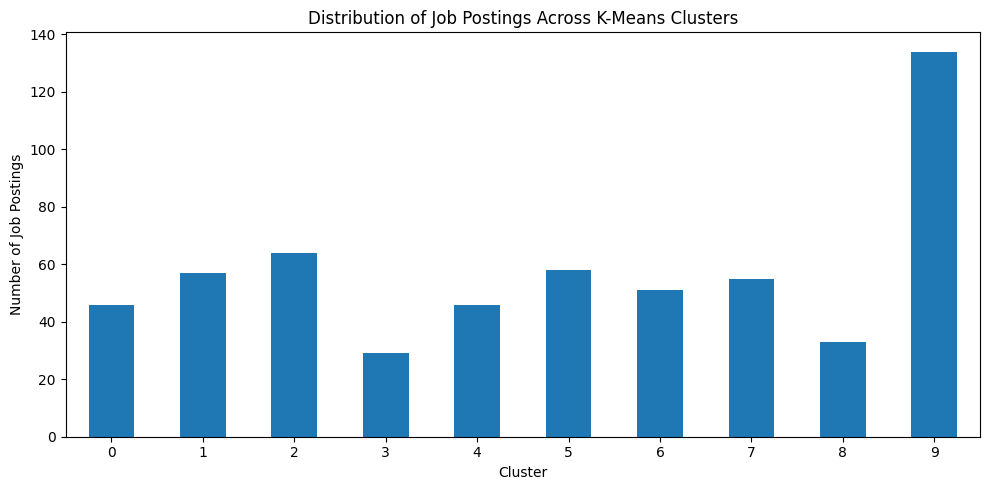

In [147]:
import matplotlib.pyplot as plt

cluster_sizes = clustered_jobs["cluster"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
cluster_sizes.plot(kind="bar")

plt.title("Distribution of Job Postings Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**6-save our clustered dataset**

In [148]:
clustered_jobs.to_csv(
    "../data/processed/ai_jobs_clustered.csv",
    index=True
)

## Phase 6: interpreting and visualizing the clusters

**1 — Identify the most important skills in each cluster**

In [149]:
# Calculate skill prevalence within each cluster
skill_columns = X_skills.columns

cluster_skill_profile = (
    clustered_jobs.groupby("cluster")[skill_columns]
    .mean()
    .mul(100)
    .round(1)
)

print("Skill prevalence (%) by cluster:")
display(cluster_skill_profile)


Skill prevalence (%) by cluster:


,has_ai,has_artificial_intelligence,has_big_data,has_cloud,has_computer_vision,has_dashboard,has_data_mining,has_data_structure,has_data_visualization,has_database,...,has_nlp,has_powerbi,has_preprocessing,has_python,has_pytorch,has_r,has_sql,has_stat,has_tableau,has_tensorflow
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,2.2,2.2,0.0,0.0,6.5,0.0,0.0,100.0,...,0.0,0.0,0.0,6.5,0.0,0.0,10.9,0.0,0.0,0.0
1,0.0,0.0,1.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.5,0.0,1.8,0.0,1.8,1.8,0.0,100.0,0.0,1.8
2,0.0,0.0,7.8,0.0,0.0,0.0,0.0,0.0,1.6,0.0,...,1.6,1.6,1.6,100.0,3.1,15.6,3.1,17.2,3.1,3.1
3,0.0,0.0,3.4,0.0,0.0,0.0,0.0,100.0,3.4,6.9,...,0.0,0.0,0.0,3.4,0.0,0.0,0.0,3.4,0.0,0.0
4,100.0,0.0,6.5,0.0,2.2,0.0,0.0,0.0,0.0,0.0,...,2.2,0.0,0.0,6.5,4.3,0.0,0.0,2.2,0.0,2.2
5,1.7,1.7,8.6,0.0,0.0,0.0,3.4,0.0,0.0,0.0,...,0.0,0.0,0.0,15.5,0.0,0.0,0.0,19.0,0.0,0.0
6,0.0,0.0,5.9,0.0,0.0,3.9,100.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,3.9,17.6,0.0,0.0
7,0.0,0.0,3.6,1.8,0.0,5.5,3.6,0.0,100.0,3.6,...,0.0,0.0,9.1,7.3,0.0,0.0,5.5,14.5,14.5,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.1,...,0.0,0.0,0.0,9.1,0.0,0.0,6.1,6.1,0.0,0.0


**2 — Visualize the skill profiles**

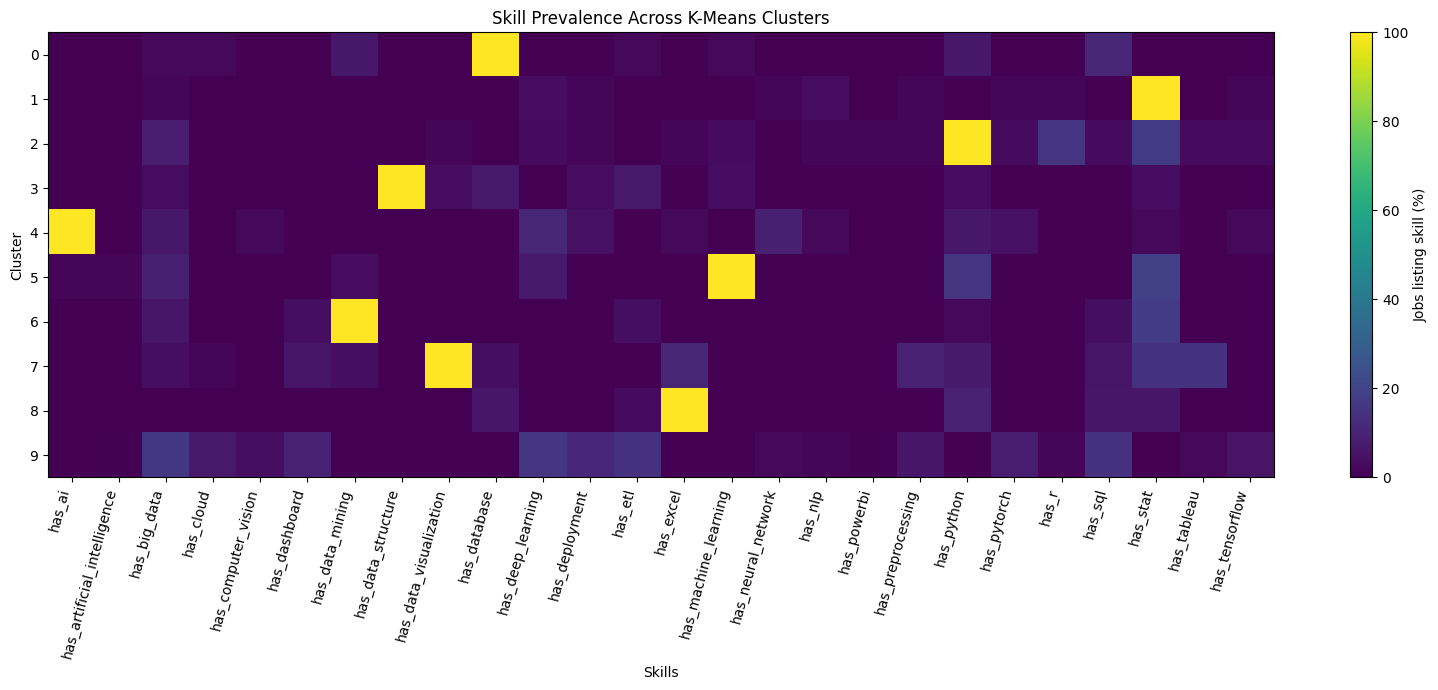

In [150]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.imshow(
    cluster_skill_profile,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Jobs listing skill (%)")
plt.xticks(
    range(len(skill_columns)),
    skill_columns,
    rotation=75,
    ha="right"
)
plt.yticks(
    range(len(cluster_skill_profile)),
    cluster_skill_profile.index
)

plt.title("Skill Prevalence Across K-Means Clusters")
plt.xlabel("Skills")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


**3 — Give each cluster a descriptive summary**

In [151]:

top_skills_by_cluster = {}

for cluster_id, profile in cluster_skill_profile.iterrows():
    top_skills = profile.sort_values(ascending=False).head(3)

    top_skills_by_cluster[cluster_id] = top_skills

    print(f"\nCluster {cluster_id}")
    print(f"Number of jobs: {(clustered_jobs['cluster'] == cluster_id).sum()}")

    for skill, percentage in top_skills.items():
        print(f"  {skill}: {percentage:.1f}%")



Cluster 0
Number of jobs: 46
  has_database: 100.0%
  has_sql: 10.9%
  has_data_mining: 6.5%

Cluster 1
Number of jobs: 57
  has_stat: 100.0%
  has_deep_learning: 3.5%
  has_nlp: 3.5%

Cluster 2
Number of jobs: 64
  has_python: 100.0%
  has_stat: 17.2%
  has_r: 15.6%

Cluster 3
Number of jobs: 29
  has_data_structure: 100.0%
  has_database: 6.9%
  has_etl: 6.9%

Cluster 4
Number of jobs: 46
  has_ai: 100.0%
  has_deep_learning: 10.9%
  has_neural_network: 8.7%

Cluster 5
Number of jobs: 58
  has_machine_learning: 100.0%
  has_stat: 19.0%
  has_python: 15.5%

Cluster 6
Number of jobs: 51
  has_data_mining: 100.0%
  has_stat: 17.6%
  has_big_data: 5.9%

Cluster 7
Number of jobs: 55
  has_data_visualization: 100.0%
  has_tableau: 14.5%
  has_stat: 14.5%

Cluster 8
Number of jobs: 33
  has_excel: 100.0%
  has_python: 9.1%
  has_stat: 6.1%

Cluster 9
Number of jobs: 134
  has_big_data: 16.4%
  has_deep_learning: 15.7%
  has_etl: 14.2%


**4-interpreting the clusters and preparing our conclusions**

**4.1 — Build a cluster summary**

In [152]:

cluster_summary = []

for cluster_id, profile in cluster_skill_profile.iterrows():

    cluster_size = (
        clustered_jobs["cluster"] == cluster_id
    ).sum()

    top_skills = (
        profile.sort_values(ascending=False)
        .head(3)
    )

    cluster_summary.append({
        "cluster": cluster_id,
        "number_of_jobs": cluster_size,
        "percentage_of_jobs": round(
            cluster_size / len(clustered_jobs) * 100, 2
        ),
        "top_skills": ", ".join(
            f"{skill.replace('has_', '')} ({percentage:.1f}%)"
            for skill, percentage in top_skills.items()
            if percentage > 0
        )
    })

cluster_summary = pd.DataFrame(cluster_summary)

display(cluster_summary)


,cluster,number_of_jobs,percentage_of_jobs,top_skills
0,0,46,8.03,"database (100.0%), sql (10.9%), data_mining (6..."
1,1,57,9.95,"stat (100.0%), deep_learning (3.5%), nlp (3.5%)"
2,2,64,11.17,"python (100.0%), stat (17.2%), r (15.6%)"
3,3,29,5.06,"data_structure (100.0%), database (6.9%), etl ..."
4,4,46,8.03,"ai (100.0%), deep_learning (10.9%), neural_net..."
5,5,58,10.12,"machine_learning (100.0%), stat (19.0%), pytho..."
6,6,51,8.90,"data_mining (100.0%), stat (17.6%), big_data (..."
7,7,55,9.60,"data_visualization (100.0%), tableau (14.5%), ..."
8,8,33,5.76,"excel (100.0%), python (9.1%), stat (6.1%)"
9,9,134,23.39,"big_data (16.4%), deep_learning (15.7%), etl (..."


**4.2 — Export the summary**

In [153]:
cluster_summary.to_csv(
    "../data/processed/cluster_summary.csv",
    index=False
)

**4.3 — Interpret your clusters**

## Interpretation of K-Means Clustering Results

*The K-Means algorithm was trained using 10 clusters and binary skill features extracted from 573 job postings with recorded skills. The model achieved a silhouette score of 0.4237, suggesting some separation between the resulting groups.*

*The cluster profiles reveal several skill-centered groups, including Database, Statistics, Python, Artificial Intelligence, Machine Learning, Data Mining, Data Visualization, and Excel. These results illustrate how job postings can be grouped according to their recorded technical skill requirements.*

*Cluster 9 is the largest group, containing 134 postings (23.39% of the analyzed dataset). Its most frequent individual skill is Big Data, appearing in 16.4% of postings, suggesting a more diverse distribution of recorded skills than in the other clusters.*

*However, these clusters should not be interpreted as definitive job categories. They represent similarities in recorded skills, and the analysis excludes postings with unknown skill information. The results therefore describe the available skill data rather than the entire job market.*